# Frozen Lake — tabular Q-learning

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/racousin/data_science_practice/blob/main/website/public/modules/ms2a-machine-learning-practice/challenges/mlp-s9-frozenlake-q-learning.ipynb)

**MS2A — Machine Learning Practice · Session 9, Reinforcement Learning**

The agent does not know the map nor the dynamics of the lake: it learns a table
$Q(s, a)$ from its own episodes, then acts greedily on it. The table you obtain on the
slippery 8x8 lake is your submission to
[challenge 202](https://ml-arena.com/viewchallenge/202), scored by the **success rate over
100 episodes**.

| Section | What you do |
|---|---|
| 1 | Look at the environment: states, actions, reward |
| 2 | Evaluate fixed policies: the baselines to beat |
| 3 | Write the ε-greedy policy and the Q-learning update |
| 4 | Train on the 4x4 lake |
| 5 | Decay ε: from exploration to exploitation |
| 6 | Train on the 8x8 lake |
| 7 | Write `agent.py`, submit, read the leaderboard |

Target: beat the benchmark (always move right, ≈ 0.25) and reach ≈ 0.6.

## 0. Setup

In [1]:
!pip install -q "gymnasium==1.3.0" "mlarena-sdk>=4.6"

import mlarena
import numpy as np
import gymnasium as gym
import matplotlib.pyplot as plt

API_TOKEN = "mlk_user_be8edd1568655ff0_bbfbb4ff5c006ef6b5f81d63b919a32c"   # <-- paste your token (Profile page)
CHALLENGE_ID = 202

client = mlarena.connect(api_key=API_TOKEN, base_url="https://ml-arena.com")
rng = np.random.default_rng(0)

zsh:1: command not found: pip


## 1. The environment

The lake is a grid: **S** start, **F** frozen (safe), **H** hole (the episode ends with
reward 0), **G** goal (the episode ends with reward 1). A state is the cell index
`row * ncol + col`; an action is 0 left, 1 down, 2 right, 3 up. By default the ice is
**slippery**: the agent moves in the intended direction with probability 1/3, and in each
of the two perpendicular directions with probability 1/3.

In [2]:
env4 = gym.make("FrozenLake-v1", map_name="4x4")
env8 = gym.make("FrozenLake-v1", map_name="8x8")

print(env4.unwrapped.desc.astype(str))
print("states:", env4.observation_space, "| actions:", env4.action_space)

[['S' 'F' 'F' 'F']
 ['F' 'H' 'F' 'H']
 ['F' 'F' 'F' 'H']
 ['H' 'F' 'F' 'G']]
states: Discrete(16) | actions: Discrete(4)


The model is exposed in `env.unwrapped.P[s][a]`: a list of `(probability, next_state,
reward, terminated)`. The agent will **not** use it; we read it once to see the slip.

In [3]:
for p, s2, r, done in env4.unwrapped.P[0][2]:   # state 0, action "right"
    print(f"p={p:.2f} -> state {s2}, reward {r}, terminated {done}")

p=0.33 -> state 4, reward 0, terminated False
p=0.33 -> state 1, reward 0, terminated False
p=0.33 -> state 0, reward 0, terminated False


**Questions**
- How many states and actions does each lake have? How many entries does a Q-table hold for
  the 8x8 lake?
- The reward is 1 at the goal and 0 everywhere else. What does $Q(s, a)$ equal for every
  pair until the agent has reached the goal once? What does that imply for an agent that
  never explores?
- Is the transition model deterministic? What does the slip change about the best path
  along a row of holes?

## 2. Evaluate a policy

A deterministic policy is a table `policy[s] -> a`. `evaluate` plays it greedily on
seeded episodes and returns the success rate: the score the leaderboard computes, over
more episodes.

In [4]:
def evaluate(env, policy, n=1000, seed=0):
    """Success rate of a deterministic policy (array of one action per state)."""
    wins = 0.0
    for i in range(n):
        s, _ = env.reset(seed=seed + i)
        done = False
        while not done:
            s, r, terminated, truncated, _ = env.step(int(policy[s]))
            wins += r
            done = terminated or truncated
    return wins / n

for name, env in [("4x4", env4), ("8x8", env8)]:
    n_s = env.observation_space.n
    print(name, "random:", evaluate(env, rng.integers(0, 4, n_s)),
          "| always right:", evaluate(env, np.full(n_s, 2)))

4x4 random: 0.024 | always right: 0.024
8x8 random: 0.001 | always right: 0.234


**Questions**
- The leaderboard scores 100 episodes. If the true success rate is $p = 0.6$, what is the
  standard deviation of the score, $\sqrt{p(1-p)/100}$? Is a difference of 0.03 between
  two submissions meaningful?
- Why do we evaluate on a fixed list of seeds?

## 3. Q-learning

Q-learning estimates the optimal action value $Q^*(s, a)$ from transitions
$(S_t, A_t, R_{t+1}, S_{t+1})$, with no model of the environment:

$$Q(S_t,A_t) \leftarrow Q(S_t,A_t) + \alpha \big(R_{t+1} + \gamma \max_a Q(S_{t+1},a) - Q(S_t,A_t)\big)$$

The term in parentheses is the **TD error**. When $S_{t+1}$ is terminal its value is 0, so
the target is $R_{t+1}$ alone.

It is **off-policy**: the agent learns the greedy policy while it behaves
**ε-greedily**: with probability ε a random action (explore), otherwise the action of
highest $Q$ (exploit).

**Exercise 1.** Write the ε-greedy choice. When several actions share the maximum (at
the start, all of them), pick one at random among them.

In [5]:
def epsilon_greedy(q_s, epsilon):
    """q_s: the 4 action values of one state. Returns an action index."""
    if rng.random() < epsilon:
        return  # TODO: a random action
    return  # TODO: an action of maximal value, ties broken at random

**Exercise 2.** Complete the agent: a Q-table of zeros of shape `(n_states, n_actions)`
and the update above in `train`. `done` is `terminated` (a hole or the goal), not
`truncated`: an episode cut after 200 steps does not end in a state of value 0.

In [6]:
class QAgent:
    def __init__(self, env, gamma=0.99, alpha=0.1, epsilon=0.1):
        self.gamma, self.alpha, self.epsilon = gamma, alpha, epsilon
        self.q = None  # TODO: the Q-table

    def act(self, s):
        return epsilon_greedy(self.q[s], self.epsilon)

    def train(self, s, a, r, s2, done):
        target = None  # TODO: r + gamma * max_a Q(s2, a), or r if done
        td_error = None  # TODO
        self.q[s, a] += None  # TODO

    def end_episode(self):
        pass

The training loop is given: one call to `train` per step, one to `end_episode` per episode.

In [7]:
def run_training(env, agent, n_episodes):
    rewards = np.zeros(n_episodes)
    for i in range(n_episodes):
        s, _ = env.reset()
        done = False
        while not done:
            a = agent.act(s)
            s2, r, terminated, truncated, _ = env.step(a)
            agent.train(s, a, r, s2, terminated)
            s, done = s2, terminated or truncated
            rewards[i] += r
        agent.end_episode()
    return rewards

def plot_rewards(rewards_by_name, window=100):
    for name, rewards in rewards_by_name.items():
        plt.plot(np.convolve(rewards, np.ones(window) / window, mode="valid"), label=name)
    plt.xlabel("episode"); plt.ylabel(f"success rate (moving average, {window})")
    plt.legend(); plt.show()

## 4. Train on the 4x4 lake

In [8]:
agent4 = QAgent(env4, epsilon=0.1)
rewards4 = run_training(env4, agent4, 3000)
plot_rewards({"Q-learning, ε = 0.1": rewards4})
print("greedy success rate:", evaluate(env4, agent4.q.argmax(axis=1)))

TypeError: 'NoneType' object is not subscriptable

**Questions**
- The training curve and the greedy evaluation measure two different policies. Which ones?
  Why is the greedy success rate higher?
- Print `agent4.q.argmax(axis=1).reshape(4, 4)`. Next to a hole, does the greedy action
  point toward the goal or away from the hole? Why, on slippery ice?
- Set `epsilon=0` and train again. What happens, and how does it relate to the sparse
  reward of Section 1?

## 5. From exploration to exploitation

A constant ε keeps exploring at the end, when $Q$ is already good. A common schedule
starts at ε = 1 (pure exploration) and multiplies ε by a factor after each episode, down
to a floor:

$$\varepsilon_{k+1} = \max(\varepsilon_{\min},\ \lambda\, \varepsilon_k)$$

**Exercise 3.** Write `end_episode` in `DecayAgent`.

In [9]:
class DecayAgent(QAgent):
    def __init__(self, env, decay=0.999, epsilon_min=0.05, **kwargs):
        super().__init__(env, epsilon=1.0, **kwargs)
        self.decay, self.epsilon_min = decay, epsilon_min

    def end_episode(self):
        pass  # TODO: epsilon <- max(epsilon_min, decay * epsilon)

In [10]:
decay4 = DecayAgent(env4)
plot_rewards({"ε = 0.1": rewards4, "ε decay": run_training(env4, decay4, 3000)})
print("greedy success rate:", evaluate(env4, decay4.q.argmax(axis=1)))

NameError: name 'rewards4' is not defined

**Questions**
- After how many episodes does ε reach its floor with `decay=0.999`? With `0.9999`?
- Why does the decaying agent's training curve start lower and end higher?

## 6. The 8x8 lake

Same code, 64 states, a goal 14 moves away at best, and many more holes. The goal is now
rarely reached by chance, so ε decays more slowly (`0.9995`) over more episodes (10,000,
about a minute).

In [11]:
agent8 = DecayAgent(env8, decay=0.9995)
rewards8 = run_training(env8, agent8, 10000)
plot_rewards({"8x8, ε decay": rewards8})
policy8 = agent8.q.argmax(axis=1)
print("greedy success rate:", evaluate(env8, policy8))
print(np.array(list("←↓→↑"))[policy8].reshape(8, 8))

TypeError: 'NoneType' object is not subscriptable

**Questions**
- Compare with always-right (≈ 0.23) and the optimal policy computed from the known
  model (≈ 0.63 with γ = 0.99). Where is the remaining gap: too little training, too much
  exploration at the end, or the noise of the evaluation?
- Try `gamma` in {0.9, 0.99, 0.999}. A small γ values a goal 30 steps away at $\gamma^{30}$.
  Why does that change the greedy action next to a hole?
- Try `alpha` in {0.01, 0.1, 0.5}. The transitions are random: what does a large α do to
  the estimate of $Q$?
- Train the same agent with `decay=0.999` over 5,000 episodes, several times. Why does it
  sometimes stay near 0.1, and what does that say about stopping exploration too early?

Keep the agent with the best greedy success rate.

## 6a. My model: stable, model-free Q-learning

Run this section independently of the unfinished teaching exercises (install
`gymnasium==1.3.0` if needed). No API token is required for local training/evaluation.

The Q-tables start at zero and learn **only from `reset`/`step` episodes**, using the
notebook's unchanged training loop, reward, and greedy evaluation. Improvements:
longer exploration, a visit-dependent learning rate, and averaging late Q-tables from
three training seeds. No map, transition model, reward shaping, or hardcoded route is used.

We keep the notebook's exact environment call: in Gymnasium 1.3.0 it has a
**100-step limit**, including on the 8×8 map. All comparisons use that same limit.
Six discount factors and two averaging methods are selected on 2,000 validation
episodes; the chosen policy is frozen before a separate 10,000-episode test.


In [12]:
from pathlib import Path
from types import SimpleNamespace
from time import perf_counter
import json

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

if gym.__version__ != "1.3.0":
    raise RuntimeError('Install the notebook version: %pip install "gymnasium==1.3.0"')

MODEL_DIR = Path.cwd()
if (MODEL_DIR / "S9 -Reinforcement Learning").is_dir():
    MODEL_DIR = MODEL_DIR / "S9 -Reinforcement Learning"

def make_lake():
    return gym.make("FrozenLake-v1", map_name="8x8")

# The notebook's two functions, unchanged, so the section can run independently.
def evaluate(env, policy, n=1000, seed=0):
    """Success rate of a deterministic policy (array of one action per state)."""
    wins = 0.0
    for i in range(n):
        s, _ = env.reset(seed=seed + i)
        done = False
        while not done:
            s, r, terminated, truncated, _ = env.step(int(policy[s]))
            wins += r
            done = terminated or truncated
    return wins / n


def run_training(env, agent, n_episodes):
    rewards = np.zeros(n_episodes)
    for i in range(n_episodes):
        s, _ = env.reset()
        done = False
        while not done:
            a = agent.act(s)
            s2, r, terminated, truncated, _ = env.step(a)
            agent.train(s, a, r, s2, terminated)
            s, done = s2, terminated or truncated
            rewards[i] += r
        agent.end_episode()
    return rewards


env8 = make_lake()
assert env8.observation_space.n == 64 and env8.action_space.n == 4
print(f"Gymnasium {gym.__version__}; slippery 8x8; "
      f"time limit = {env8.spec.max_episode_steps} steps")


Gymnasium 1.3.0; slippery 8x8; time limit = 100 steps


In [13]:
class SampledQAgent:
    """Tabular Q-learning; no access to the map or transition probabilities."""
    def __init__(self, env, seed, gamma=.99, alpha=.1, decay=.9995,
                 epsilon_min=.05, alpha_decay=False, average_after=None):
        self.q = np.zeros((env.observation_space.n, env.action_space.n))
        self.visits = np.zeros_like(self.q, dtype=np.int64)
        self.rng = np.random.default_rng(seed)
        self.gamma, self.alpha = gamma, alpha
        self.decay, self.epsilon_min = decay, epsilon_min
        self.epsilon = 1.
        self.alpha_decay = alpha_decay
        self.episode = 0
        self.average_after = average_after
        self.q_sum = np.zeros_like(self.q)
        self.n_snapshots = 0

    def act(self, s):
        if self.rng.random() < self.epsilon:
            return int(self.rng.integers(self.q.shape[1]))
        values = self.q[s]
        best = np.flatnonzero(values == values.max())
        return int(best[0] if len(best) == 1 else self.rng.choice(best))

    def train(self, s, a, r, s2, done):
        self.visits[s, a] += 1
        alpha = self.alpha
        if self.alpha_decay:
            alpha = self.alpha / (1. + self.visits[s, a] / 100.) ** .6
        # Only true termination removes the bootstrap; truncation does not.
        target = r if done else r + self.gamma * self.q[s2].max()
        self.q[s, a] += alpha * (target - self.q[s, a])

    def end_episode(self):
        self.epsilon = max(self.epsilon_min, self.decay * self.epsilon)
        self.episode += 1
        if (self.average_after is not None and self.episode >= self.average_after
                and self.episode % 100 == 0):
            self.q_sum += self.q
            self.n_snapshots += 1


In [3]:
# Set True to reproduce all training instead of loading the measured run cache.
RETRAIN = False
TRAIN_SEEDS = [11, 29, 47]
GAMMAS = [.975, .98, .985, .99, .995, .999]
BASE_EPISODES, MODEL_EPISODES = 10_000, 60_000
BASE_CONFIG = dict(gamma=.99, alpha=.1, decay=.9995, epsilon_min=.05,
                   alpha_decay=False, average_after=None)
MODEL_CONFIG = dict(alpha=.3, decay=.9999, epsilon_min=.05,
                    alpha_decay=True, average_after=40_000)
config_json = json.dumps(dict(gymnasium=gym.__version__, environment="FrozenLake-v1",
                             map_name="8x8", max_episode_steps=100,
                             train_seeds=TRAIN_SEEDS, gammas=GAMMAS,
                             baseline_episodes=BASE_EPISODES, model_episodes=MODEL_EPISODES,
                             baseline=BASE_CONFIG, model=MODEL_CONFIG), sort_keys=True)
CACHE_PATH = MODEL_DIR / "training_runs.npz"

def train_one(seed, episodes, **config):
    lake = make_lake()
    lake.reset(seed=seed)
    learner = SampledQAgent(lake, seed=seed, **config)
    started = perf_counter()
    rewards = run_training(lake, learner, episodes)
    seconds = perf_counter() - started
    lake.close()
    tail_q = (learner.q_sum / learner.n_snapshots
              if learner.n_snapshots else learner.q.copy())
    return learner.q, tail_q, rewards, seconds

if CACHE_PATH.is_file() and not RETRAIN:
    with np.load(CACHE_PATH, allow_pickle=False) as cache:
        if str(cache["config_json"]) != config_json:
            raise RuntimeError("Training settings changed: set RETRAIN = True.")
        runs = {key: cache[key].copy() for key in cache.files if key != "config_json"}
    print("Loaded the measured, seeded training runs from", CACHE_PATH.name)
else:
    baseline_runs = [train_one(seed, BASE_EPISODES, **BASE_CONFIG)
                     for seed in TRAIN_SEEDS]
    candidate_runs = []
    for gamma in GAMMAS:
        candidate_runs.append([train_one(seed, MODEL_EPISODES, gamma=gamma,
                                         **MODEL_CONFIG) for seed in TRAIN_SEEDS])
        print(f"Finished gamma={gamma} on all {len(TRAIN_SEEDS)} training seeds")
    runs = dict(
        baseline_q=np.stack([run[0] for run in baseline_runs]),
        baseline_rewards=np.stack([run[2] for run in baseline_runs]),
        baseline_seconds=np.array([run[3] for run in baseline_runs]),
        candidate_q=np.array([[run[0] for run in group] for group in candidate_runs]),
        candidate_tail_q=np.array([[run[1] for run in group] for group in candidate_runs]),
        candidate_rewards=np.array([[run[2] for run in group] for group in candidate_runs]),
        candidate_seconds=np.array([[run[3] for run in group] for group in candidate_runs]),
    )
    np.savez_compressed(CACHE_PATH, config_json=config_json, **runs)

assert runs["baseline_q"].shape == (3, 64, 4)
assert runs["candidate_q"].shape == (len(GAMMAS), 3, 64, 4)
assert np.isfinite(runs["candidate_q"]).all()
print(f"Baseline: 3 x {BASE_EPISODES:,} episodes; "
      f"{runs['baseline_seconds'].sum():.1f}s total training")
print(f"Search: {len(GAMMAS)} x 3 x {MODEL_EPISODES:,} episodes; "
      f"{runs['candidate_seconds'].sum():.1f}s total training")


Loaded the measured, seeded training runs from training_runs.npz
Baseline: 3 x 10,000 episodes; 7.5s total training
Search: 6 x 3 x 60,000 episodes; 323.6s total training


In [4]:
VAL_N, VAL_SEED = 2_000, 100_000

# Every candidate gets the same validation episodes. No test scores are used here.
baseline_val = [evaluate(env8, q.argmax(axis=1), n=VAL_N, seed=VAL_SEED)
                for q in runs["baseline_q"]]
baseline_index = int(np.argmax(baseline_val))
candidates = {}
for i, gamma in enumerate(GAMMAS):
    candidates[f"gamma={gamma}, final average"] = runs["candidate_q"][i].mean(axis=0)
    candidates[f"gamma={gamma}, tail average"] = runs["candidate_tail_q"][i].mean(axis=0)
validation_scores = {name: evaluate(env8, q.argmax(axis=1), n=VAL_N, seed=VAL_SEED)
                     for name, q in candidates.items()}
best_name = max(validation_scores, key=validation_scores.get)
agent8 = SimpleNamespace(q=candidates[best_name].copy())
policy8 = agent8.q.argmax(axis=1)
selected_gamma = float(best_name.split(",")[0].split("=")[1])
selected_gamma_index = GAMMAS.index(selected_gamma)

print("Original 10,000-episode model, validation by training seed:")
for seed, score in zip(TRAIN_SEEDS, baseline_val):
    print(f"  seed {seed}: {score:.2%}")
print("\nCandidate validation success (three training seeds averaged):")
for name, score in sorted(validation_scores.items(), key=lambda item: -item[1]):
    print(f"  {name:34s} {score:.2%}")
print("\nFrozen selection:", best_name)


Original 10,000-episode model, validation by training seed:
  seed 11: 61.15%
  seed 29: 46.40%
  seed 47: 60.40%

Candidate validation success (three training seeds averaged):
  gamma=0.98, final average          63.85%
  gamma=0.98, tail average           63.85%
  gamma=0.99, final average          63.50%
  gamma=0.99, tail average           63.45%
  gamma=0.985, tail average          63.30%
  gamma=0.985, final average         63.20%
  gamma=0.975, tail average          61.40%
  gamma=0.975, final average         61.05%
  gamma=0.995, tail average          58.30%
  gamma=0.995, final average         58.25%
  gamma=0.999, final average         50.95%
  gamma=0.999, tail average          50.95%

Frozen selection: gamma=0.98, final average


In [5]:
# This block is run only after the choice above is frozen.
TEST_N, TEST_SEED = 10_000, 200_000

def wilson_interval(p, n, z=1.959963984540054):
    denominator = 1 + z*z/n
    centre = (p + z*z/(2*n)) / denominator
    half = z * np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / denominator
    return float(centre-half), float(centre+half)

right_score = evaluate(env8, np.full(64, 2), n=TEST_N, seed=TEST_SEED)
baseline_test = [evaluate(env8, q.argmax(axis=1), n=TEST_N, seed=TEST_SEED)
                 for q in runs["baseline_q"]]
model_score = evaluate(env8, policy8, n=TEST_N, seed=TEST_SEED)
rows = [("Always right", right_score),
        (f"Original Q-learning (validation-selected seed {TRAIN_SEEDS[baseline_index]})",
         baseline_test[baseline_index]),
        ("My Q-learning ensemble", model_score)]
print(f"Held-out test: {TEST_N:,} episodes, seeds {TEST_SEED}..{TEST_SEED+TEST_N-1}")
for name, score in rows:
    low, high = wilson_interval(score, TEST_N)
    print(f"{name:57s} {score:6.2%}  (95% CI {low:.2%}–{high:.2%})")
print("Original model, all three training seeds:",
      ", ".join(f"{seed}: {score:.2%}" for seed, score in zip(TRAIN_SEEDS, baseline_test)))
print(f"Original model mean across training seeds: {np.mean(baseline_test):.2%}")
print(f"Gain over always-right: {100*(model_score-right_score):+.2f} percentage points")
print(f"Gain over validation-selected original model: "
      f"{100*(model_score-baseline_test[baseline_index]):+.2f} percentage points")

report = dict(config=json.loads(config_json), selected=best_name,
              validation=dict(n=VAL_N, seed=VAL_SEED, candidates=validation_scores,
                              baseline_by_training_seed=dict(zip(map(str, TRAIN_SEEDS), baseline_val))),
              test=dict(n=TEST_N, seed=TEST_SEED, always_right=right_score,
                        original_by_training_seed=dict(zip(map(str, TRAIN_SEEDS), baseline_test)),
                        original_selected_seed=TRAIN_SEEDS[baseline_index],
                        original_selected=baseline_test[baseline_index],
                        original_mean=float(np.mean(baseline_test)),
                        model=model_score, model_95ci=wilson_interval(model_score, TEST_N)),
              training_seconds=dict(baseline=float(runs["baseline_seconds"].sum()),
                                    search=float(runs["candidate_seconds"].sum())))
(MODEL_DIR / "model_report.json").write_text(json.dumps(report, indent=2) + "\n")


Held-out test: 10,000 episodes, seeds 200000..209999
Always right                                              22.42%  (95% CI 21.61%–23.25%)
Original Q-learning (validation-selected seed 11)         61.51%  (95% CI 60.55%–62.46%)
My Q-learning ensemble                                    63.47%  (95% CI 62.52%–64.41%)
Original model, all three training seeds: 11: 61.51%, 29: 45.79%, 47: 61.02%
Original model mean across training seeds: 56.11%
Gain over always-right: +41.05 percentage points
Gain over validation-selected original model: +1.96 percentage points


1894

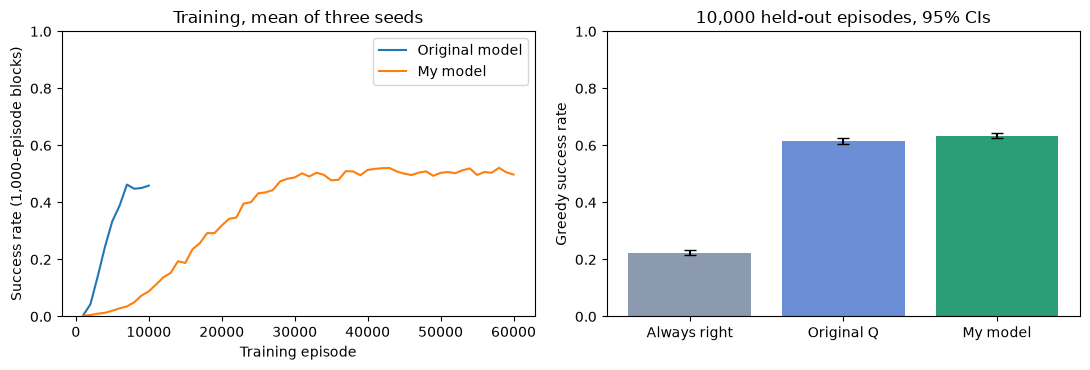

In [6]:
# Training includes exploratory actions; the test above is entirely greedy.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for label, values in [("Original model", runs["baseline_rewards"]),
                      ("My model", runs["candidate_rewards"][selected_gamma_index])]:
    window = 1_000
    blocks = values.reshape(len(TRAIN_SEEDS), -1, window).mean(axis=2)
    axes[0].plot(np.arange(1, blocks.shape[1]+1)*window,
                 blocks.mean(axis=0), label=label)
axes[0].set(xlabel="Training episode", ylabel="Success rate (1,000-episode blocks)",
            title="Training, mean of three seeds", ylim=(0, 1))
axes[0].legend()
scores = [row[1] for row in rows]
intervals = np.array([wilson_interval(score, TEST_N) for score in scores])
axes[1].bar(["Always right", "Original Q", "My model"], scores,
            color=["#8c9aaf", "#6b8ed6", "#2b9d77"],
            yerr=np.stack([np.array(scores)-intervals[:, 0],
                           intervals[:, 1]-np.array(scores)]), capsize=4)
axes[1].set(ylabel="Greedy success rate", title="10,000 held-out episodes, 95% CIs", ylim=(0, 1))
fig.tight_layout()
plt.show()


In [7]:
# Preserve the exact agent.py interface from section 7.
np.save(MODEL_DIR / "q_table.npy", agent8.q)
agent_source = """from pathlib import Path

import numpy as np


class Agent:
    def __init__(self):
        self.q = np.load(Path(__file__).parent / "q_table.npy")

    def setup(self, observation_space, action_space):
        return True

    def choose_action(self, observation, reward=0.0, terminated=False,
                      truncated=False, info=None, action_mask=None):
        if terminated or truncated:
            return None
        return int(np.argmax(self.q[int(observation)]))
"""
(MODEL_DIR / "agent.py").write_text(agent_source)

import importlib.util
spec = importlib.util.spec_from_file_location("frozenlake_submission", MODEL_DIR / "agent.py")
submission_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(submission_module)
player = submission_module.Agent()
assert player.setup(None, None)
predictions = np.array([player.choose_action(s) for s in range(64)])
assert np.array_equal(predictions, policy8)
assert player.choose_action(0, terminated=True) is None
assert player.choose_action(0, truncated=True) is None
assert np.load(MODEL_DIR / "q_table.npy", allow_pickle=False).shape == (64, 4)
print("Saved agent.py and q_table.npy; all 64 predictions match the tested policy.")
print("Section 7's local 100-episode agent.py check:",
      evaluate(env8, predictions, n=100, seed=1000))
print("Greedy actions by state (same format as the original notebook):")
print(np.array(list("←↓→↑"))[predictions].reshape(8, 8))


Saved agent.py and q_table.npy; all 64 predictions match the tested policy.
Section 7's local 100-episode agent.py check: 0.61
Greedy actions by state (same format as the original notebook):
[['↑' '→' '→' '→' '→' '→' '→' '→']
 ['↑' '↑' '↑' '↑' '↑' '→' '→' '↓']
 ['↑' '↑' '←' '←' '→' '↑' '→' '↓']
 ['↑' '↑' '↑' '↑' '←' '←' '→' '→']
 ['↑' '↑' '←' '←' '→' '↓' '↑' '→']
 ['←' '←' '←' '↓' '↑' '←' '←' '→']
 ['←' '←' '→' '↑' '←' '→' '←' '→']
 ['←' '↓' '←' '←' '↓' '→' '↓' '←']]


### Additional performance audit

The gain over the strong original run is modest. A finer, model-free search checked
37 discount factors (0.974–0.992), two initial learning rates, and two averaging
methods: 148 candidates from three fresh 100,000-episode training streams. Tables
received one ordinary Q-learning update per shared sampled transition; the original
64×4 table, rewards, training loop, greedy predictions, and 100-step limit were retained.

Selection used 5,000 fresh validation episodes. The 148 candidates produced only
eight distinct greedy policies, including the existing ensemble. A frozen challenger
was then compared on **20,000 further test episodes**, with the same seeds for all models:

| Model | Success rate |
|---|---:|
| Original 10,000-episode Q-learning | 61.405% |
| Existing ensemble | 63.575% |
| Finer-search winner | 63.610% |

The extra gain over the existing ensemble is **0.035 percentage points**;
its paired 95% interval is [-0.181, 0.251] points.
This search did not find a substantial improvement. The exported model is retained.

The complete audit is reproducible with `python refinement_audit.py` from this folder;
its settings and measurements are saved in `refinement_report.json`.


## 7. Submit

The platform runs `agent.py` with your table next to it. Save the table, then write the
agent: at each step it receives the cell index and returns the greedy action.

In [ ]:
np.save("q_table.npy", agent8.q)

In [ ]:
%%writefile agent.py
from pathlib import Path

import numpy as np


class Agent:
    def __init__(self):
        self.q = np.load(Path(__file__).parent / "q_table.npy")

    def setup(self, observation_space, action_space):
        return True

    def choose_action(self, observation, reward=0.0, terminated=False,
                      truncated=False, info=None, action_mask=None):
        if terminated or truncated:
            return None
        return int(np.argmax(self.q[int(observation)]))

Check it locally, the way the platform calls it:

In [ ]:
import importlib, agent
importlib.reload(agent)

player = agent.Agent()
player.setup(None, None)
print("success rate of agent.py:",
      evaluate(env8, [player.choose_action(s) for s in range(64)], n=100, seed=1000))

In [ ]:
result = client.submit(challenge_id=CHALLENGE_ID, files=["agent.py", "q_table.npy"],
                       submission_name="q-learning-8x8", wait=True)
print(result["status"])

In [ ]:
client.leaderboard(CHALLENGE_ID)

## Going further

- Your score varies by about ±0.05 between runs of 100 episodes: compare candidates with
  `evaluate(..., n=1000)`, not with the leaderboard.
- Average several Q-tables trained with different seeds, or train longer with a slower
  decay.
- The same `QAgent` runs on any discrete environment: try `Taxi-v3` and `CliffWalking-v1`.